<a id="objective"></a>
# Los Angeles Restaurant Market Research

## Project Objective

The purpose of this project is to analyze the restaurant market in Los Angeles
and identify characteristics that could support the opening of a café with
robot waiters.

The analysis will examine establishment types, chain status, seating capacity,
and restaurant locations. Based on the results, recommendations will be made
regarding the most appropriate type of establishment, number of seats, and
potential for developing a chain.

### Table of Contents

- [Project Objective](#objective)
1. [Data Loading and Preparation](#data-preparation)
2. [Data Analysis](#data-analysis)
   - [2.1 Proportions of Establishment Types](#establishment-types)
   - [2.2 Chain and Non-Chain Establishments](#chain-status)
   - [2.3 Establishment Types Typical of Chains](#chain-types)
   - [2.4 Number of Establishments and Seats in Chains](#chain-seats)
   - [2.5 Average Number of Seats by Establishment Type](#average-seats)
   - [2.6 Street Name Extraction](#street-analysis)
   - [2.7 Top 10 Streets by Number of Restaurants](#top-streets)
   - [2.8 Streets with Only One Restaurant](#single-restaurant-streets)
   - [2.9 Seat Distribution on Popular Streets](#seat-distribution)
3. [Conclusions and Recommendations](#conclusions)


<a id="data-preparation"></a>

## 1. Data Loading and Preparation

In this section, the dataset will be loaded and examined. Column names, data
types, missing values, and duplicate rows will be checked before the analysis.

In [1]:
# Import the libraries required for data analysis and visualization
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load the Los Angeles restaurant dataset
rest_data = pd.read_csv('data/rest_data_us_upd.csv')

# Display the first five rows
rest_data.head()

,id,object_name,address,chain,object_type,number
0,11786,HABITAT COFFEE SHOP,3708 N EAGLE ROCK BLVD,False,Cafe,26
1,11787,REILLY'S,100 WORLD WAY 120,False,Restaurant,9
2,11788,STREET CHURROS,6801 HOLLYWOOD BLVD 253,False,Fast Food,20
3,11789,TRINITI ECHO PARK,1814 W SUNSET BLVD,False,Restaurant,22
4,11790,POLLEN,2100 ECHO PARK AVE,False,Restaurant,20


In [3]:
# Display general information about the dataset
rest_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9651 entries, 0 to 9650
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   id           9651 non-null   int64 
 1   object_name  9651 non-null   object
 2   address      9651 non-null   object
 3   chain        9648 non-null   object
 4   object_type  9651 non-null   object
 5   number       9651 non-null   int64 
dtypes: int64(2), object(4)
memory usage: 452.5+ KB


In [4]:
# Display the number of rows and columns
rest_data.shape

(9651, 6)

In [5]:
# Count missing values in each column
rest_data.isna().sum()

id             0
object_name    0
address        0
chain          3
object_type    0
number         0
dtype: int64

In [6]:
# Display the rows with missing values the chain column
rest_data[rest_data['chain'].isna()]

,id,object_name,address,chain,object_type,number
7408,19194,TAQUERIA LOS 3 CARNALES,5000 E WHITTIER BLVD,NaN,Restaurant,14
7523,19309,JAMMIN JIMMY'S PIZZA,1641 FIRESTONE BLVD,NaN,Pizza,1
8648,20434,THE LEXINGTON THEATER,129 E 3RD ST,NaN,Restaurant,35


### Missing Values

Three missing values were identified in the `chain` column. Because there is
not enough information to determine whether these establishments belong to a
chain, the missing values cannot be reliably replaced. Since these records
represent approximately 0.03% of the dataset, they will be removed.

In [7]:
# Remove rows with missing values in the chain columns
rest_data = rest_data.dropna(subset=['chain']).copy()

# Confirm that no missing values remain
rest_data.isna().sum()

id             0
object_name    0
address        0
chain          0
object_type    0
number         0
dtype: int64

In [8]:
# Count completely duplicated rows
rest_data.duplicated().sum()

np.int64(0)

In [9]:
# Display the unique values in the chain column
rest_data['chain'].unique()

array([False, True], dtype=object)

In [10]:
# Convert the chain column to the Boolean data type
rest_data['chain'] = rest_data['chain'].astype(bool)

# Confirm the new data type of the chain column
rest_data['chain'].dtype

dtype('bool')

In [11]:
# Check for duplicated establishement IDs
rest_data['id'].duplicated().sum()

np.int64(0)

### Data Preparation Summary

The dataset initially contained 9,651 rows and 6 columns. Three missing values
were found in the `chain` column. Since these records represented approximately
0.03% of the dataset and their chain status could not be reliably determined,
they were removed.

No completely duplicated rows or duplicated establishment IDs were found.
After removing the missing values, the `chain` column was converted from the
`object` data type to the Boolean data type. The prepared dataset contains
9,648 rows and is ready for analysis.

<a id="data-analysis"></a>

## 2. Data Analysis

This section analyzes the characteristics of restaurants in Los Angeles,
including establishment types, chain status, seating capacity, and location.

<a id="establishment-types"></a>
### 2.1 Proportions of Establishment Types

In [12]:
# Count the number of establishments in each category
type_counts = rest_data['object_type'].value_counts()

type_counts

object_type
Restaurant    7253
Fast Food     1066
Cafe           435
Pizza          319
Bar            292
Bakery         283
Name: count, dtype: int64

In [13]:
# Calculate the percentage of each establishment type
type_proportions = (
    type_counts / type_counts.sum() * 100
).round(2)

type_proportions

object_type
Restaurant    75.18
Fast Food     11.05
Cafe           4.51
Pizza          3.31
Bar            3.03
Bakery         2.93
Name: count, dtype: float64

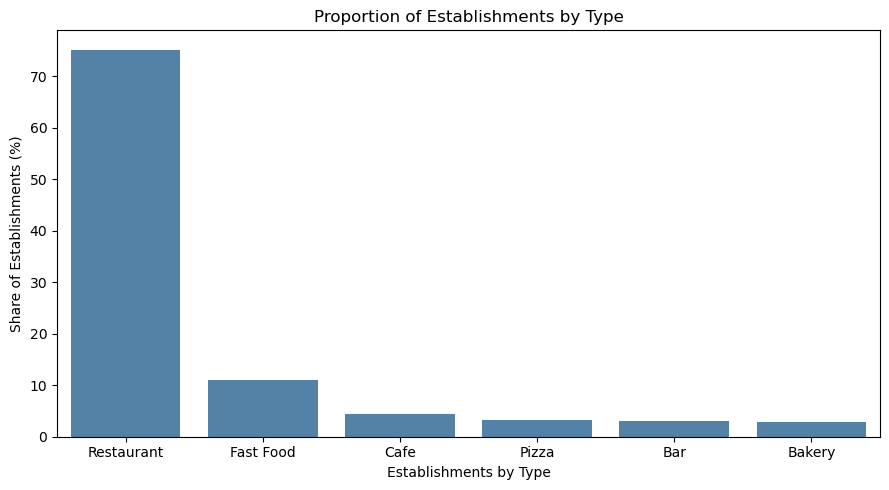

In [14]:
# Create a bar chart showing the proportion of each establishment type
plt.figure(figsize=(9,5))

ax = sns.barplot(
    x=type_proportions.index,
    y=type_proportions.values,
    color='steelblue'
)

# Add the chart title and axis labels
ax.set_title('Proportion of Establishments by Type')
ax.set_xlabel('Establishments by Type')
ax.set_ylabel('Share of Establishments (%)')

plt.tight_layout()
plt.show()

#### Findings

Restaurants are the dominant establishment type, representing 75.18% of all
establishments. Fast-food establishments rank second at 11.05%. Cafés, pizzerias,
bars, and bakeries each represent less than 5% of the market.

This indicates that the Los Angeles food-service market is strongly concentrated
in the restaurant category, while cafés occupy a considerably smaller share.

<a id="chain-status"></a>

### 2.2 Chain and Non-Chain Establishments

In [15]:
# Count chain and non-chain establishments
chain_counts = rest_data['chain'].value_counts()

chain_counts

chain
False    5972
True     3676
Name: count, dtype: int64

In [16]:
# Calculate the percentage of chain and non-chain establishments
chain_proportions = (
    chain_counts / chain_counts.sum() * 100
).round(2)

chain_proportions

chain
False    61.9
True     38.1
Name: count, dtype: float64

In [17]:
# Replace Boolean labels with descriptive category names
chain_plot = chain_proportions.rename(
    index={
        False: 'Non-chain',
        True: 'Chain'
    }
)

chain_plot

chain
Non-chain    61.9
Chain        38.1
Name: count, dtype: float64

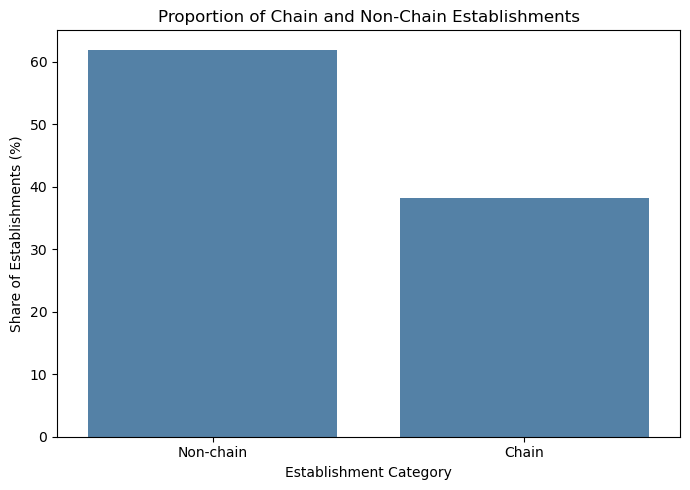

In [18]:
# Create a bar chart showing the proportion of chain establishments
plt.figure(figsize=(7, 5))

ax = sns.barplot(
    x=chain_plot.index,
    y=chain_plot.values,
    color='steelblue'
)

# Add the chart title and axis labels
ax.set_title('Proportion of Chain and Non-Chain Establishments')
ax.set_xlabel('Establishment Category')
ax.set_ylabel('Share of Establishments (%)')


plt.tight_layout()
plt.show()

#### Findings

Non-chain establishments represent 61.9% of the market, while chain
establishments account for 38.1%. Independent establishments are therefore the
majority, although restaurant chains still represent a substantial share of
the Los Angeles market.

<a id="chain-types"></a>

### 2.3 Establishment Types Typical of Chains

In [19]:
# Count Chain establishments in each category
chain_type_counts = (
    rest_data[rest_data['chain'] == True]['object_type'].value_counts()
)

chain_type_counts

object_type
Restaurant    2292
Fast Food      605
Bakery         283
Cafe           266
Pizza          153
Bar             77
Name: count, dtype: int64

In [20]:
# Calculate the percentage of chain establishments within each type

chain_share_by_type = (
    chain_type_counts / type_counts *100
).round(2).sort_values(ascending=False)

chain_share_by_type

object_type
Bakery        100.00
Cafe           61.15
Fast Food      56.75
Pizza          47.96
Restaurant     31.60
Bar            26.37
Name: count, dtype: float64

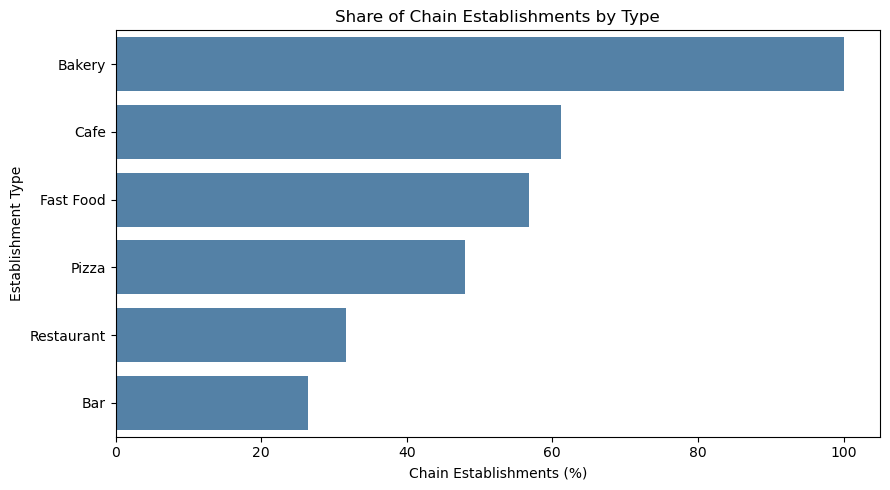

In [21]:
# Create a horizontal bar chart of chain percentages by establishment type
plt.figure(figsize=(9,5))

ax = sns.barplot(
    x= chain_share_by_type.values,
    y= chain_share_by_type.index,
    color= 'steelblue'
)

# Add the chart title and axis labels
ax.set_title('Share of Chain Establishments by Type')
ax.set_xlabel('Chain Establishments (%)')
ax.set_ylabel('Establishment Type')

plt.tight_layout()
plt.show()

#### Findings

Bakeries are the establishment type most typically associated with chains. In
this dataset, 100% of bakeries belong to a chain. Cafés and fast-food
establishments also commonly operate as chains, with shares of 61.15% and
56.75%, respectively.

Although restaurants have the largest absolute number of chain establishments,
only 31.60% of all restaurants belong to a chain.

<a id="chain-seats"></a>

### 2.4 Number of Establishments and Seats in Chains

In [22]:
# Select only chain establishments
chain_data = rest_data[rest_data['chain'] == True]

chain_data.head()

,id,object_name,address,chain,object_type,number
8,11794,ABC DONUTS,3027 N SAN FERNANDO RD UNIT 103,True,Fast Food,1
10,11796,EL POLLO LOCO,5319 W SUNSET BLVD,True,Restaurant,38
11,11797,POONG NYUN BAKERY,928 S WESTERN AVE STE 109,True,Bakery,17
12,11798,EMC RESTAURANT GROUP LLC,3500 W 6TH ST STE 101,True,Restaurant,133
14,11800,CUSCATLECA BAKERY,2501 W SUNSET BLVD #A,True,Bakery,26


In [23]:
# Count the number of establishments in each chain
chain_establishment_count = (
    chain_data.groupby('object_name')['id']
        .count()
        .sort_values(ascending=False)
)

chain_establishment_count.head()

object_name
THE COFFEE BEAN & TEA LEAF    47
SUBWAY                        31
DOMINO'S PIZZA                15
WABA GRILL                    14
KENTUCKY FRIED CHICKEN        14
Name: id, dtype: int64

In [24]:
# Calculate the average number of seats in each chain
chain_average_seats = (
    chain_data
    .groupby('object_name')['number']
    .mean()
)

chain_average_seats.head()

object_name
#1 CHINESE FAST FOOD      6.0
1810 RESTAURANT          45.0
333                     180.0
3RD ST MARKET & DELI      7.0
4 CAMINOS RESTAURANT     18.0
Name: number, dtype: float64

In [25]:
# Combine the establishment counts and average seat numbers
chain_summary = pd.concat(
    [chain_establishment_count, chain_average_seats],
    axis=1
)

# Rename the columns to make them easier to understand
chain_summary.columns = [
    'establishment_count',
    'average_seats'
]

chain_summary.head()

,establishment_count,average_seats
object_name,,
THE COFFEE BEAN & TEA LEAF,47,26.723404
SUBWAY,31,16.419355
DOMINO'S PIZZA,15,12.333333
WABA GRILL,14,42.857143
KENTUCKY FRIED CHICKEN,14,33.357143


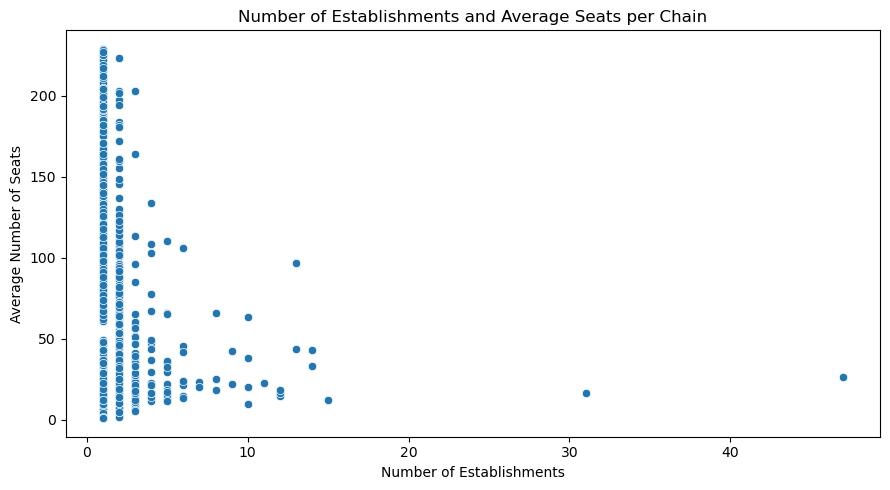

In [26]:
# Create a scatter plot of chain size and average seating capacity
plt.figure(figsize=(9,5))

sns.scatterplot(
    data= chain_summary,
    x= 'establishment_count',
    y= 'average_seats'
)

# Add the chart title and axis labels
plt.title('Number of Establishments and Average Seats per Chain')
plt.xlabel('Number of Establishments')
plt.ylabel('Average Number of Seats')

plt.tight_layout()

plt.show()

#### Findings

Names associated with many establishments tend to have relatively small average seating capacity, while names with fewer establishments show a wider range. This is a descriptive pattern, not evidence that chain size causes seating capacity to change.

**Limitation:** Groups use exact `object_name` matches among establishments flagged as chains. Spelling variants and location-specific suffixes can split one brand into multiple groups. These counts therefore describe matching names in this dataset, not verified brand-wide chain sizes.

<a id="average-seats"></a>

### 2.5 Average Number of Seats by Establishment Type

In [27]:
# Calculate the average number of seats for each establishment type
average_seats_by_type = (
    rest_data.groupby('object_type')['number']
    .mean()
    .sort_values(ascending=False)
)

average_seats_by_type

object_type
Restaurant    48.048807
Bar           44.767123
Fast Food     31.837711
Pizza         28.545455
Cafe          25.000000
Bakery        21.773852
Name: number, dtype: float64

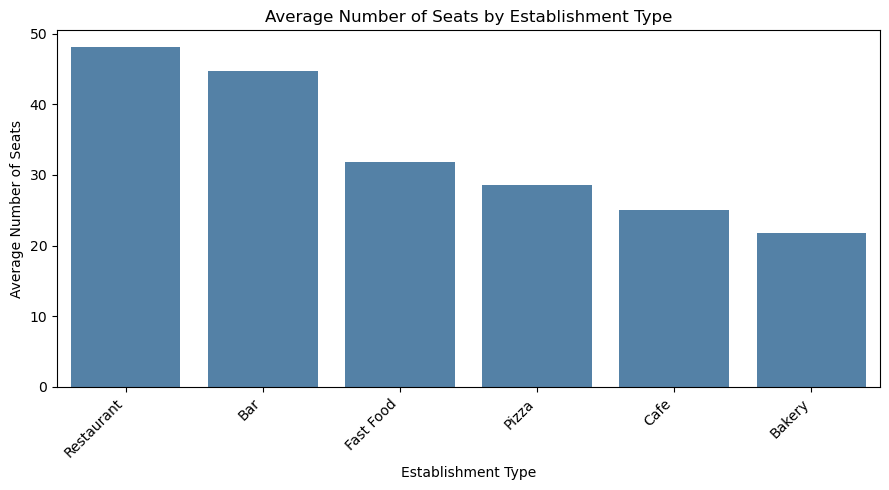

In [28]:
# Create a bar chart of average seats by establishment type
plt.figure(figsize=(9,5))

sns.barplot(
    x=average_seats_by_type.index,
    y=average_seats_by_type.values,
    color='steelblue'
)

# Add the chart title and axis labels
plt.title('Average Number of Seats by Establishment Type')
plt.xlabel('Establishment Type')
plt.ylabel('Average Number of Seats')

# Improve the readability of category labels
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

#### Findings

Restaurants have the highest average seating capacity, with approximately
48 seats per establishment. Bars follow closely, with an average of about
45 seats.

After these two categories, the average drops considerably. Fast-food
establishments have approximately 32 seats on average, while pizzerias, cafés,
and bakeries have fewer than 30 seats. Bakeries have the lowest average seating
capacity, at approximately 22 seats.

<a id="street-analysis"></a>

### 2.6 Street Analysis

In [29]:
# Display examples of restaurant addresses
rest_data['address'].head(10)

0             3708 N EAGLE ROCK BLVD
1                  100 WORLD WAY 120
2            6801 HOLLYWOOD BLVD 253
3                 1814 W SUNSET BLVD
4                 2100 ECHO PARK AVE
5                10004 NATIONAL BLVD
6                  100 WORLD WAY 126
7              3500 W 6TH ST STE 226
8    3027 N SAN FERNANDO RD UNIT 103
9               3707 N CAHUENGA BLVD
Name: address, dtype: object

In [30]:
# Create the street_name column by removing the street number
rest_data['street_name'] = rest_data['address'].str.replace(
    r'^\d+\s+',
    '',
    regex=True
)

# Remove unit or suite information that appears after the street name
rest_data['street_name'] = rest_data['street_name'].str.replace(
    r'\s+(?:STE|SUITE|UNIT|FLR|FLOOR|FC)\b.*$',
    '',
    regex=True
)

# Remove apartment or unit information beginning with #
rest_data['street_name'] = rest_data['street_name'].str.replace(
    r'\s+#.*$',
    '',
    regex=True
)

# Remove unit numbers that appear at the end of the address
rest_data['street_name'] = rest_data['street_name'].str.replace(
    r'\s+\d+$',
    '',
    regex=True
)

# Remove fractional building numbers that remain at the beginning
rest_data['street_name'] = rest_data['street_name'].str.replace(
    r'^\d+/\d+\s+',
    '',
    regex=True
)

# Remove the extra "LOS" text that appears after some street names
rest_data['street_name'] = rest_data['street_name'].str.replace(
    r'\s+LOS$',
    '',
    regex=True
)

# Remove extra spaces at the beginning or end of the street name
rest_data['street_name'] = rest_data['street_name'].str.strip()


In [31]:
# Display a sample of the cleaned street names
rest_data[['address', 'street_name']].head(20)

,address,street_name
0,3708 N EAGLE ROCK BLVD,N EAGLE ROCK BLVD
1,100 WORLD WAY 120,WORLD WAY
2,6801 HOLLYWOOD BLVD 253,HOLLYWOOD BLVD
3,1814 W SUNSET BLVD,W SUNSET BLVD
4,2100 ECHO PARK AVE,ECHO PARK AVE
5,10004 NATIONAL BLVD,NATIONAL BLVD
6,100 WORLD WAY 126,WORLD WAY
7,3500 W 6TH ST STE 226,W 6TH ST
8,3027 N SAN FERNANDO RD UNIT 103,N SAN FERNANDO RD
9,3707 N CAHUENGA BLVD,N CAHUENGA BLVD


In [32]:
# Check for street names that may still contain unremoved address details
suspicious_streets = rest_data[
    rest_data['street_name'].str.contains(
        r'#|\b(?:STE|SUITE|UNIT|FLR|FLOOR|FC)\b',
        regex=True,
        na=False
    )
][['address', 'street_name']]

# Display the number of potentially problematic street names
print('Potentially problematic street names:', len(suspicious_streets))

# Display examples for inspection
suspicious_streets.head(20)

Potentially problematic street names: 1


,address,street_name
4673,110 E 9TH ST ST B LOB#2,E 9TH ST ST B LOB#2


### Finding

Street names were extracted using rule-based removal of building numbers and common unit or suite information. The diagnostic uses word boundaries so that a valid name such as WESTERN is not flagged solely because it contains STE.

This is a heuristic rather than geocoding. Unusual addresses, spelling variants, and directional prefixes may still split or merge locations. Street rankings should be treated as exploratory and manually validated before site selection. Counts include all establishment types, not only the Restaurant category.

After execution, one address remains flagged: `110 E 9TH ST ST B LOB#2`. It has been left unchanged pending manual verification. The 767 single-establishment street labels should not be interpreted as 767 independently verified physical streets.

<a id="top-streets"></a>

### 2.7 Top 10 Streets by Number of Establishments

In [33]:
# Count the number of establishments on each street
street_counts = rest_data['street_name'].value_counts()

# Select the 10 streets with the highest number of establishments
top_10_streets = street_counts.head(10)

# Display the results
top_10_streets

street_name
WILSHIRE BLVD        357
W SUNSET BLVD        355
W PICO BLVD          335
S WESTERN AVE        258
SANTA MONICA BLVD    246
HOLLYWOOD BLVD       232
W OLYMPIC BLVD       227
S FIGUEROA ST        219
W 3RD ST             218
S VERMONT AVE        207
Name: count, dtype: int64

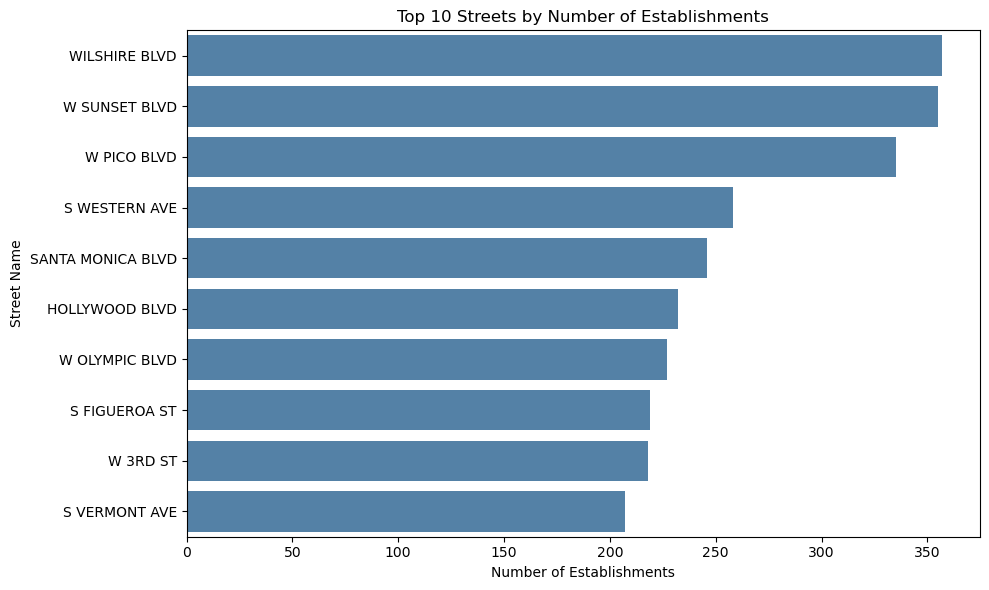

In [34]:
# Create a horizontal bar chart of the ten streets with the most establishments
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_10_streets.values,
    y=top_10_streets.index,
    color='steelblue'
)

# Add the chart title and axis labels
plt.title('Top 10 Streets by Number of Establishments')
plt.xlabel('Number of Establishments')
plt.ylabel('Street Name')

plt.tight_layout()
plt.show()

#### Findings

Wilshire Blvd has the largest number of establishments, with 357 establishments,
followed very closely by W Sunset Blvd with 355. W Pico Blvd ranks third with
335 establishments.

The difference between the two leading streets is very small, while the number
of establishments gradually decreases across the remaining streets. All ten streets
have more than 200 establishments, indicating a strong concentration of
establishments along these locations.

<a id="single-restaurant-streets"></a>

### 2.8 Streets with Only One Establishment

In [35]:
# Count the number of streets with only one establishment
single_restaurant_streets = (street_counts == 1).sum()

# Display the result
print(
    'Number of streets with only one establishment:',
    single_restaurant_streets
)

Number of streets with only one establishment: 767


#### Findings

A total of 767 streets have only one establishment. This shows that, although
establishments are highly concentrated on a small number of popular streets,
many other streets contain only a single establishment.

<a id="seat-distribution"></a>

### 2.9 Seat Distribution on Popular Streets

In [36]:
# Get the names of the 10 streets with the highest number of establishments
top_10_street_names = top_10_streets.index

# Filter the dataset to include only establishments located on the top 10 streets
top_streets_data = rest_data[
    rest_data['street_name'].isin(top_10_street_names)
]

# Display the first rows of the filtered dataset
top_streets_data[['street_name', 'number']].head()

,street_name,number
2,HOLLYWOOD BLVD,20
3,W SUNSET BLVD,22
10,W SUNSET BLVD,38
11,S WESTERN AVE,17
14,W SUNSET BLVD,26


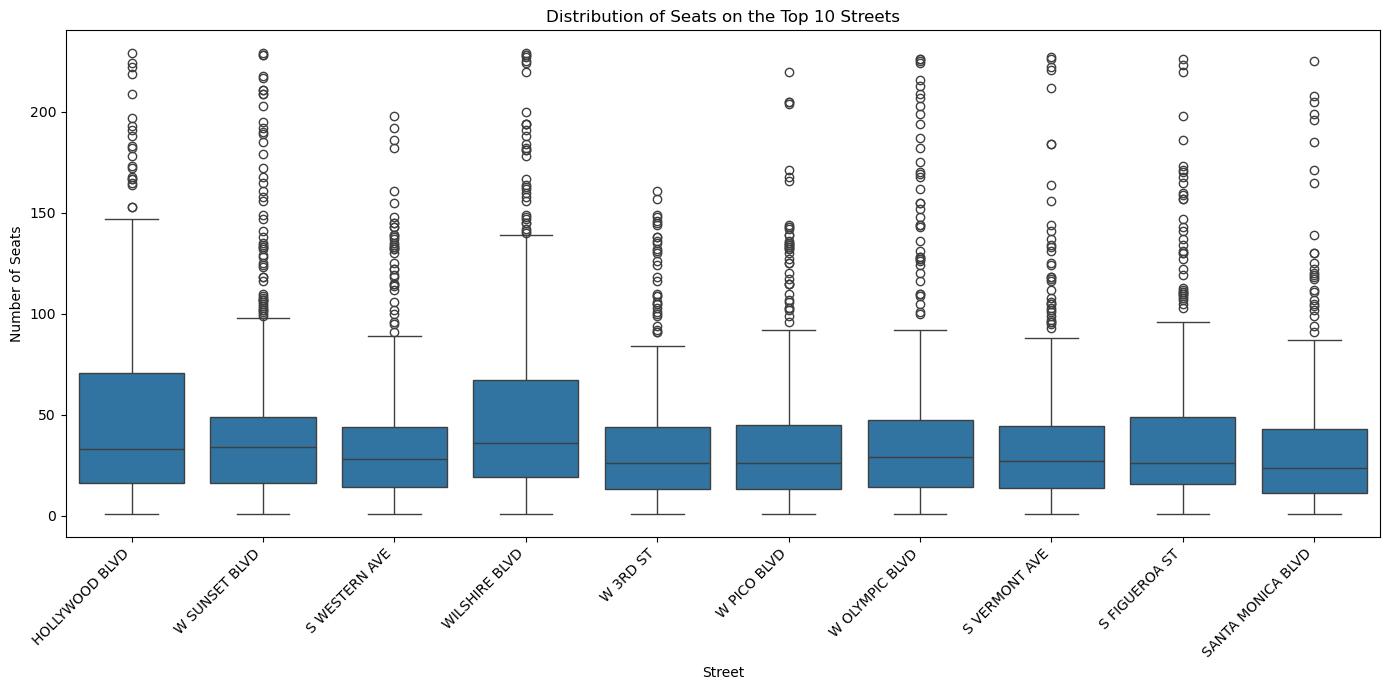

/Users/gabriellaferrazgomes/.codex/.chatgpt-projects/g-p-6a343b4920d48191b928f4e8fd528fdb/output/portfolio/los-angeles-restaurant-market-analysis/seat_distribution_top_10_streets.png

In [37]:
# Create a boxplot to analyze the distribution of seats across the 10 streets with the highest number of establishments
plt.figure(figsize=(14, 7))

sns.boxplot(
    data=top_streets_data,
    x='street_name',
    y='number'
)

# Add title and axis labels
plt.title('Distribution of Seats on the Top 10 Streets')
plt.xlabel('Street')
plt.ylabel('Number of Seats')

# Rotate street names to improve readability
plt.xticks(rotation=45, ha='right')

# Adjust the layout and display the chart
plt.tight_layout()

# Save the chart as a high-resolution PNG file
plt.savefig(
    'seat_distribution_top_10_streets.png',
    dpi=300,
    bbox_inches='tight'
)

# Display the chart
plt.show()

# Create a clickable link to download the chart
from IPython.display import FileLink

FileLink('seat_distribution_top_10_streets.png')

In [38]:
# Calculate descriptive statistics for the number of seats on each of the top 10 streets
seat_stats = (
    top_streets_data
    .groupby('street_name')['number']
    .agg(['count', 'median', 'mean', 'std', 'min', 'max'])
    .sort_values('median', ascending=False)
)

# Display the statistics
seat_stats

,count,median,mean,std,min,max
street_name,,,,,,
WILSHIRE BLVD,357,36.0,53.042017,51.755919,1,229
W SUNSET BLVD,355,34.0,48.845070,50.018033,1,229
HOLLYWOOD BLVD,232,33.0,54.500000,56.474030,1,229
W OLYMPIC BLVD,227,29.0,50.387665,56.161977,1,226
S WESTERN AVE,258,28.0,41.449612,41.988967,1,198
S VERMONT AVE,207,27.0,43.531401,47.553626,1,227
S FIGUEROA ST,219,26.0,47.146119,49.213415,1,226
W 3RD ST,218,26.0,38.261468,38.536840,1,161
W PICO BLVD,335,26.0,39.764179,41.120765,1,220


#### Findings

The median seating capacity across all ten popular streets is below 50 seats,
ranging from 23.5 seats on Santa Monica Blvd to 36 seats on Wilshire Blvd.
This indicates that a typical establishment on these streets is relatively
small or medium-sized.

The mean number of seats is higher than the median on every street, indicating
right-skewed distributions. Most streets also contain large establishments
with more than 200 seats, although these represent the upper end of the
distribution.

Overall, smaller and medium-sized establishments are more typical even on
streets with a high concentration of restaurants.

<a id="conclusions"></a>

## 3. Conclusions and Recommendations

### General Conclusion

The analysis suggests opening a compact café with approximately 25 seats, which is close to the average seating capacity observed for cafés in the dataset. Starting with a smaller pilot location could reduce the initial investment and allow the business model to be tested before expansion.

Restaurant activity is highly concentrated on several major streets, with Wilshire Blvd, W Sunset Blvd, and W Pico Blvd having the largest number of establishments. These high-concentration areas may be considered as potential locations. However, additional information about pedestrian traffic, rental costs, competition, and the target audience should be evaluated before selecting the final location.

The analysis of seating capacity on the most popular streets also shows that smaller and medium-sized establishments are more typical, supporting the idea of starting with a compact café.

If the café remains successful after the novelty of robot waiters declines, its operations could be standardized and expanded into a chain of compact cafés. The 61.15% chain share among cafés provides context for this format, but does not demonstrate that a new café would succeed as a chain. Expansion should depend on pilot economics and operational evidence.

For long-term success, the business should not depend only on robot waiters. Product quality, customer service, appropriate pricing, location, and operational efficiency will also be essential.